# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Isi Nama Kalian | Isi NRP Kalian |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [ ]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.
import os
import random
import inspect
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device yang digunakan:", device)

Device yang digunakan: cpu


In [ ]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.
# Jika dataset sudah diunduh manual, isi DATA_DIR dengan folder yang berisi kedua file CSV.
# Jika dibiarkan None, dataset diambil lewat kagglehub (memakai cache jika sudah pernah diunduh).
DATA_DIR = None
if DATA_DIR is None:
    DATA_DIR = kagglehub.dataset_download("zalando-research/fashionmnist")
print("Dataset berada di:", DATA_DIR)

def find_file(root, name):
    for dirpath, _, filenames in os.walk(root):
        if name in filenames:
            return os.path.join(dirpath, name)
    raise FileNotFoundError(f"{name} tidak ditemukan di {root}")

train_df = pd.read_csv(find_file(DATA_DIR, "fashion-mnist_train.csv"))
test_df = pd.read_csv(find_file(DATA_DIR, "fashion-mnist_test.csv"))

print("Ukuran data train:", train_df.shape)
print("Ukuran data test :", test_df.shape)
train_df.head()

Using Colab cache for faster access to the 'fashionmnist' dataset.
Dataset berada di: /kaggle/input/fashionmnist
Ukuran data train: (60000, 785)
Ukuran data test : (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


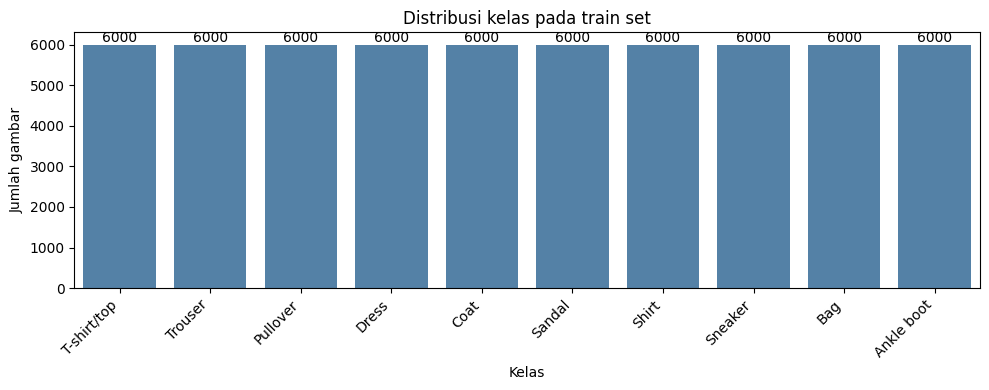

In [ ]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
label_map = {i: name for i, name in enumerate(class_names)}

plt.figure(figsize=(10, 4))
ax = sns.countplot(x=train_df["label"].map(label_map), order=class_names, color="steelblue")
ax.bar_label(ax.containers[0])
plt.xticks(rotation=45, ha="right")
plt.xlabel("Kelas")
plt.ylabel("Jumlah gambar")
plt.title("Distribusi kelas pada train set")
plt.tight_layout()
plt.show()

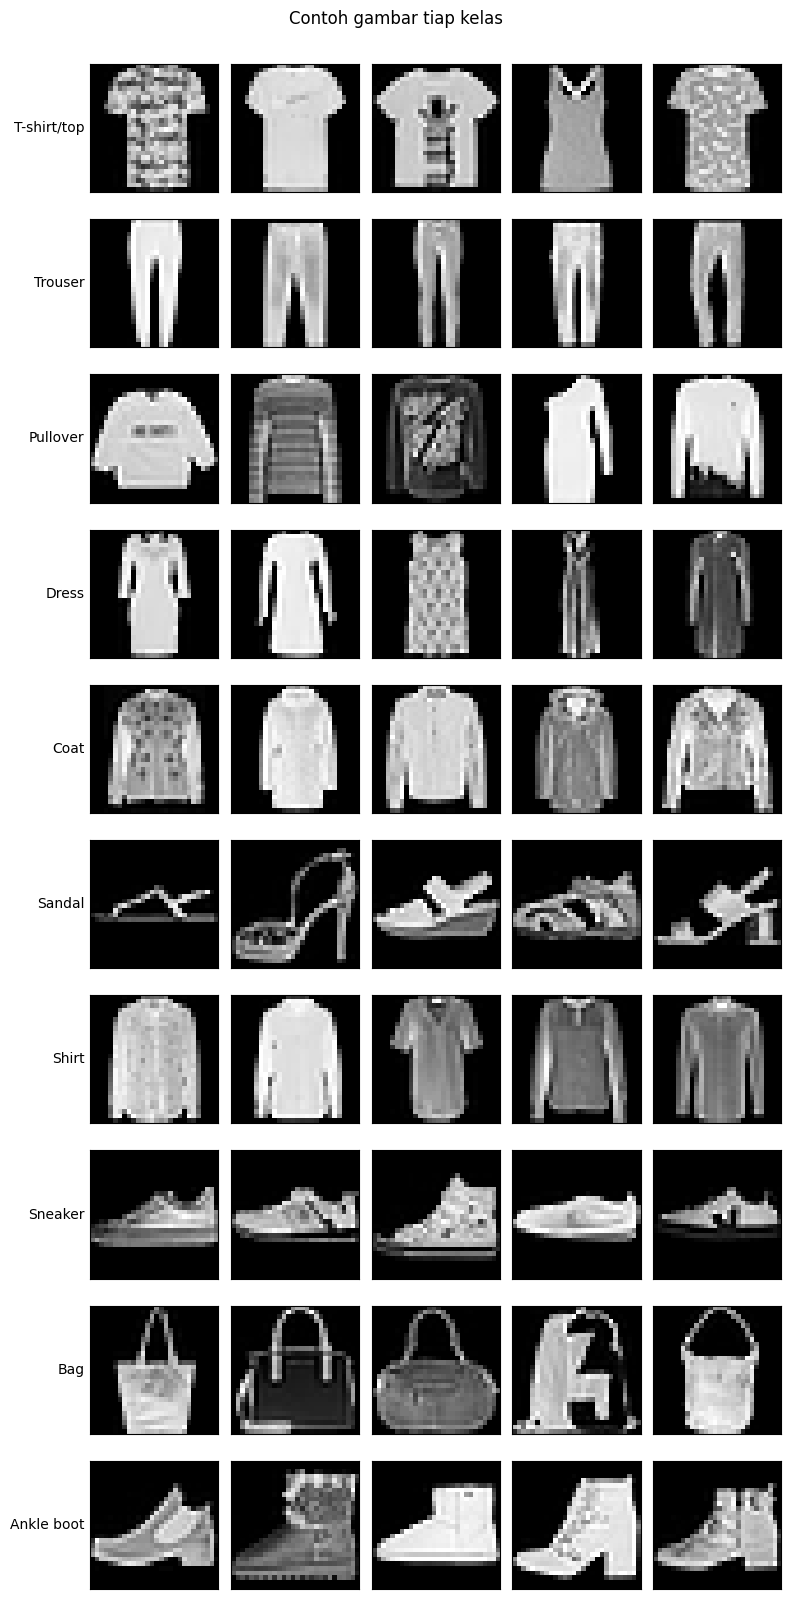

In [ ]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?
n_per_class = 5
fig, axes = plt.subplots(10, n_per_class, figsize=(n_per_class * 1.6, 10 * 1.6))
for c in range(10):
    samples = train_df[train_df["label"] == c].iloc[:n_per_class, 1:].values
    for j in range(n_per_class):
        ax = axes[c, j]
        ax.imshow(samples[j].reshape(28, 28), cmap="gray")
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(class_names[c], rotation=0, ha="right", va="center", fontsize=10)
plt.suptitle("Contoh gambar tiap kelas", y=1.0)
plt.tight_layout()
plt.show()

**Kelas yang secara visual terlihat mirip:** *T-shirt/top*, *Shirt*, *Pullover*, dan *Coat* (semuanya pakaian atasan dengan siluet persegi, perbedaannya hanya pada panjang lengan, kerah, atau kancing). Kelompok kedua adalah *Sandal*, *Sneaker*, dan *Ankle boot* (sama-sama alas kaki). *Dress* juga kadang mirip *T-shirt/top* atau *Coat*. Dugaan ini akan diperiksa kembali lewat confusion matrix pada bagian 4.

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

Missing value train: 0 | test: 0
Baris duplikat train: 43 | test: 1
Rentang nilai piksel: 0 - 255
Rata-rata intensitas piksel: 72.96 | std: 89.97

Distribusi kelas test set:
label
T-shirt/top    1000
Trouser        1000
Pullover       1000
Dress          1000
Coat           1000
Sandal         1000
Shirt          1000
Sneaker        1000
Bag            1000
Ankle boot     1000
Name: count, dtype: int64


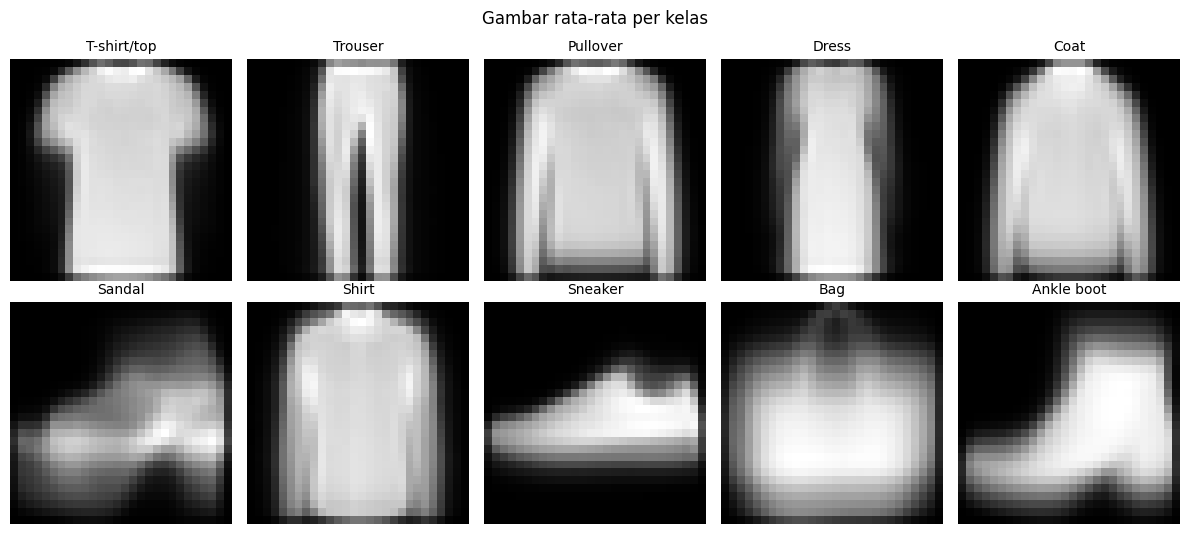

,intensitas
kelas,
T-shirt/top,82.88
Trouser,56.75
Pullover,95.72
Dress,66.20
Coat,98.16
Sandal,34.87
Shirt,85.12
Sneaker,42.84
Bag,90.04


In [ ]:
# EDA tambahan
print("Missing value train:", train_df.isnull().sum().sum(), "| test:", test_df.isnull().sum().sum())
print("Baris duplikat train:", train_df.duplicated().sum(), "| test:", test_df.duplicated().sum())
pix = train_df.drop(columns="label").values
print("Rentang nilai piksel:", pix.min(), "-", pix.max())
print("Rata-rata intensitas piksel:", round(pix.mean(), 2), "| std:", round(pix.std(), 2))
print("\nDistribusi kelas test set:")
print(test_df["label"].map(label_map).value_counts().reindex(class_names))

# Gambar rata-rata tiap kelas: memperlihatkan "bentuk umum" tiap kelas
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for c, ax in enumerate(axes.ravel()):
    mean_img = train_df[train_df["label"] == c].drop(columns="label").values.mean(axis=0).reshape(28, 28)
    ax.imshow(mean_img, cmap="gray")
    ax.set_title(class_names[c], fontsize=10)
    ax.axis("off")
plt.suptitle("Gambar rata-rata per kelas")
plt.tight_layout()
plt.show()

(train_df.assign(kelas=train_df["label"].map(label_map))
         .assign(intensitas=pix.mean(axis=1))
         .groupby("kelas")["intensitas"].mean().reindex(class_names).round(2))

**Catatan EDA:** isi bagian ini dengan temuan dari output di atas, misalnya apakah distribusi kelas seimbang, apakah ada missing value atau duplikat, serta kelas mana yang gambar rata-ratanya paling mirip satu sama lain.

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [ ]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.
y_train_full = train_df["label"].values
X_train_full = train_df.drop(columns="label").values
y_test = test_df["label"].values
X_test = test_df.drop(columns="label").values

print("X_train_full:", X_train_full.shape, "| y_train_full:", y_train_full.shape)
print("X_test      :", X_test.shape, "| y_test      :", y_test.shape)

X_train_full: (60000, 784) | y_train_full: (60000,)
X_test      : (10000, 784) | y_test      : (10000,)


In [ ]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).
X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
print("Rentang setelah normalisasi:", X_train_full.min(), "-", X_train_full.max())

Rentang setelah normalisasi: 0.0 - 1.0


In [ ]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1, stratify=y_train_full, random_state=SEED
)
print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)
print("Proporsi kelas train (min-max):", np.bincount(y_train).min(), "-", np.bincount(y_train).max())
print("Proporsi kelas val   (min-max):", np.bincount(y_val).min(), "-", np.bincount(y_val).max())

Train: (54000, 784) | Validation: (6000, 784) | Test: (10000, 784)
Proporsi kelas train (min-max): 5400 - 5400
Proporsi kelas val   (min-max): 600 - 600


In [ ]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).
BATCH_SIZE = 128

def to_tensor(X, y):
    X_t = torch.tensor(X, dtype=torch.float32).reshape(-1, 1, 28, 28)   # (N, 1, 28, 28)
    y_t = torch.tensor(y, dtype=torch.long)
    return X_t, y_t

X_train_t, y_train_t = to_tensor(X_train, y_train)
X_val_t, y_val_t = to_tensor(X_val, y_val)
X_test_t, y_test_t = to_tensor(X_test, y_test)

g = torch.Generator()
g.manual_seed(SEED)
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True, generator=g)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=BATCH_SIZE, shuffle=False)

print("X_train_t:", X_train_t.shape, X_train_t.dtype)
print("y_train_t:", y_train_t.shape, y_train_t.dtype)
print("Jumlah batch -> train:", len(train_loader), "| val:", len(val_loader), "| test:", len(test_loader))

X_train_t: torch.Size([54000, 1, 28, 28]) torch.float32
y_train_t: torch.Size([54000]) torch.int64
Jumlah batch -> train: 422 | val: 47 | test: 79


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [ ]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).
class ANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                 # (N, 1, 28, 28) -> (N, 784)
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 10),           # 10 logit, tanpa Softmax (sudah ada di CrossEntropyLoss)
        )

    def forward(self, x):
        return self.net(x)

def count_params(m):
    return sum(p.numel() for p in m.parameters())

torch.manual_seed(SEED)
ann = ANN().to(device)
print(ann)
print("Jumlah parameter ANN:", count_params(ann))

ANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter ANN: 235146


In [ ]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.
EPOCHS = 20
LR = 1e-3
criterion = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        total_loss += criterion(out, yb).item() * xb.size(0)
        correct += (out.argmax(dim=1) == yb).sum().item()
        n += xb.size(0)
    return total_loss / n, correct / n

def train_model(model, epochs=EPOCHS, lr=LR):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc, best_state, best_epoch = 0.0, None, 0

    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        tr_loss, tr_acc = evaluate(model, train_loader)
        va_loss, va_acc = evaluate(model, val_loader)
        for k, v in zip(history.keys(), (tr_loss, tr_acc, va_loss, va_acc)):
            history[k].append(v)

        if va_acc > best_val_acc:
            best_val_acc, best_epoch = va_acc, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

        print(f"Epoch {epoch:02d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f}")

    model.load_state_dict(best_state)   # kembalikan bobot ke epoch dengan val accuracy terbaik
    print(f"\nBobot terbaik diambil dari epoch {best_epoch} (val acc {best_val_acc:.4f})")
    return history, best_val_acc

history_ann, best_val_ann = train_model(ann)

Epoch 01/20 | train loss 0.4442 acc 0.8378 | val loss 0.4651 acc 0.8287
Epoch 02/20 | train loss 0.4071 acc 0.8501 | val loss 0.4312 acc 0.8435
Epoch 03/20 | train loss 0.3313 acc 0.8789 | val loss 0.3694 acc 0.8638
Epoch 04/20 | train loss 0.2997 acc 0.8904 | val loss 0.3462 acc 0.8735
Epoch 05/20 | train loss 0.2911 acc 0.8940 | val loss 0.3447 acc 0.8755
Epoch 06/20 | train loss 0.2688 acc 0.9010 | val loss 0.3289 acc 0.8817
Epoch 07/20 | train loss 0.2505 acc 0.9080 | val loss 0.3188 acc 0.8848
Epoch 08/20 | train loss 0.2383 acc 0.9129 | val loss 0.3125 acc 0.8875
Epoch 09/20 | train loss 0.2386 acc 0.9120 | val loss 0.3125 acc 0.8870
Epoch 10/20 | train loss 0.2306 acc 0.9150 | val loss 0.3152 acc 0.8840
Epoch 11/20 | train loss 0.2178 acc 0.9187 | val loss 0.3138 acc 0.8905
Epoch 12/20 | train loss 0.2119 acc 0.9194 | val loss 0.3112 acc 0.8885
Epoch 13/20 | train loss 0.2008 acc 0.9258 | val loss 0.3132 acc 0.8897
Epoch 14/20 | train loss 0.2063 acc 0.9231 | val loss 0.3251 acc

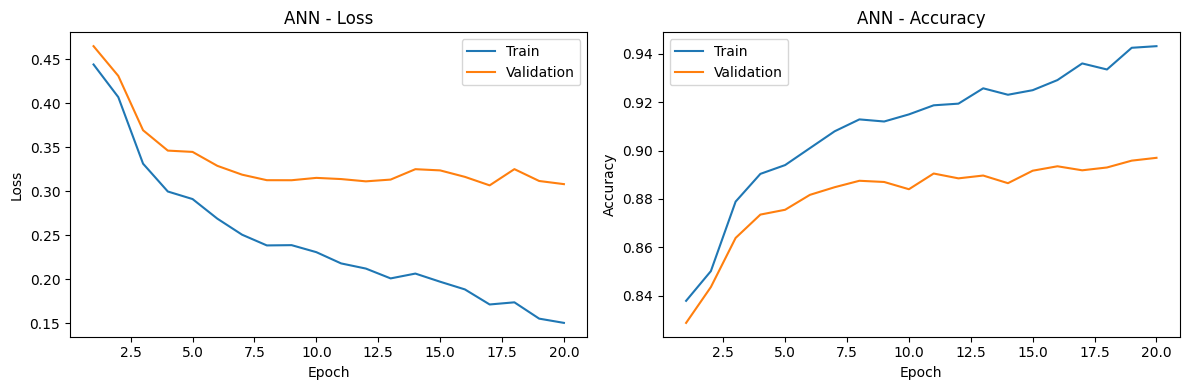

In [ ]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.
def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], label="Train")
    axes[0].plot(epochs, history["val_loss"], label="Validation")
    axes[0].set_title(f"{title} - Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()
    axes[1].plot(epochs, history["train_acc"], label="Train")
    axes[1].plot(epochs, history["val_acc"], label="Validation")
    axes[1].set_title(f"{title} - Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(history_ann, "ANN")

In [ ]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.
@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds = []
    for xb, _ in loader:
        preds.append(model(xb.to(device)).argmax(dim=1).cpu())
    return torch.cat(preds).numpy()

pred_ann = predict(ann, test_loader)
print("Test accuracy ANN:", round(accuracy_score(y_test, pred_ann), 4))

Test accuracy ANN: 0.8962


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [ ]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(SEED)
cnn = CNN().to(device)
print(cnn)
print("Jumlah parameter CNN sederhana:", count_params(cnn))

# Perhitungan manual ukuran output: (W - K + 2P) / S + 1
def out_size(W, K, P, S):
    return (W - K + 2 * P) // S + 1

w = 28
print(f"\nInput           : 1 x {w} x {w}")
w = out_size(w, 3, 1, 1); print(f"Conv1 (K3,P1,S1): (28-3+2*1)/1+1 = {w} -> 32 x {w} x {w}")
w = out_size(w, 2, 0, 2); print(f"Pool1 (K2,S2)   : (28-2+0)/2+1   = {w} -> 32 x {w} x {w}")
w = out_size(w, 3, 1, 1); print(f"Conv2 (K3,P1,S1): (14-3+2*1)/1+1 = {w} -> 64 x {w} x {w}")
w = out_size(w, 2, 0, 2); print(f"Pool2 (K2,S2)   : (14-2+0)/2+1   = {w} -> 64 x {w} x {w}")
flat_manual = 64 * w * w
print(f"Flatten         : 64 x {w} x {w} = {flat_manual}  -> input nn.Linear pertama")

# menocokkan dengan tensor dummy
dummy_out = cnn.features(torch.zeros(1, 1, 28, 28).to(device))
print("\nBentuk output bagian konvolusi (dummy):", tuple(dummy_out.shape), "| jumlah elemen:", dummy_out.numel())
assert dummy_out.numel() == flat_manual == 64 * 7 * 7

CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter CNN sederhana: 421642

Input           : 1 x 28 x 28
Conv1 (K3,P1,S1): (28-3+2*1)/1+1 = 28 -> 32 x 28 x 28
Pool1 (K2,S2)   : (28-2+0)/2+1   = 14 -> 32 x 14 x 14
Conv2 (K3,P1,S1): (14-3+2*1)/1+1 = 14 -> 64 x 14 x 14
Pool2 (K2,S2)   : (14-2+0)/2+1   = 7 -> 64 x 7 x 7
Flatten         : 64 x 7 x 7 = 3136  -> input nn.Linear pertama

Bentuk output bagian konvolusi (dummy): (1, 64, 7, 7

Epoch 01/20 | train loss 0.3515 acc 0.8754 | val loss 0.3604 acc 0.8735
Epoch 02/20 | train loss 0.3006 acc 0.8913 | val loss 0.3183 acc 0.8847
Epoch 03/20 | train loss 0.2581 acc 0.9060 | val loss 0.2834 acc 0.8995
Epoch 04/20 | train loss 0.2298 acc 0.9165 | val loss 0.2625 acc 0.9058
Epoch 05/20 | train loss 0.2153 acc 0.9224 | val loss 0.2550 acc 0.9075
Epoch 06/20 | train loss 0.1948 acc 0.9319 | val loss 0.2382 acc 0.9152
Epoch 07/20 | train loss 0.1802 acc 0.9356 | val loss 0.2307 acc 0.9168
Epoch 08/20 | train loss 0.1653 acc 0.9405 | val loss 0.2257 acc 0.9143
Epoch 09/20 | train loss 0.1516 acc 0.9457 | val loss 0.2215 acc 0.9215
Epoch 10/20 | train loss 0.1550 acc 0.9430 | val loss 0.2415 acc 0.9103
Epoch 11/20 | train loss 0.1249 acc 0.9561 | val loss 0.2143 acc 0.9233
Epoch 12/20 | train loss 0.1131 acc 0.9602 | val loss 0.2198 acc 0.9240
Epoch 13/20 | train loss 0.1044 acc 0.9629 | val loss 0.2294 acc 0.9228
Epoch 14/20 | train loss 0.0880 acc 0.9694 | val loss 0.2219 acc

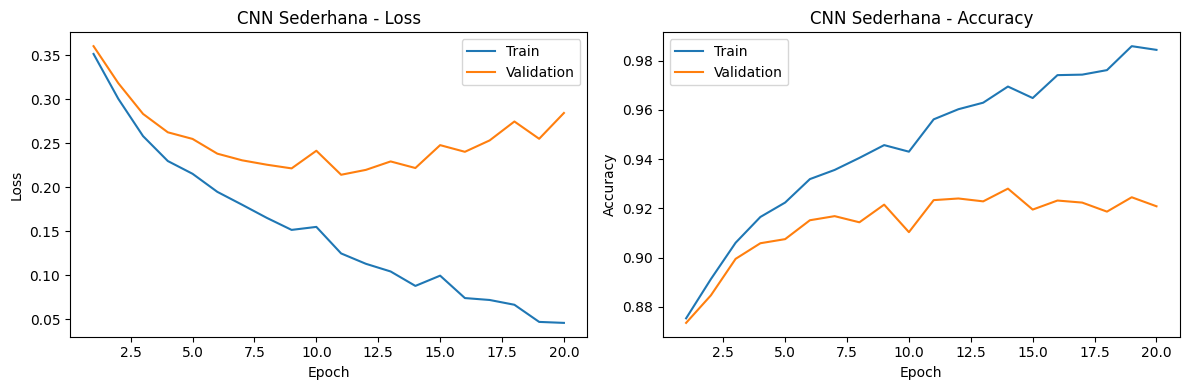

In [ ]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.
history_cnn, best_val_cnn = train_model(cnn)
plot_history(history_cnn, "CNN Sederhana")

In [ ]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
pred_cnn = predict(cnn, test_loader)
print("Test accuracy CNN sederhana:", round(accuracy_score(y_test, pred_cnn), 4))

Test accuracy CNN sederhana: 0.9262


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [ ]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.
class CNN_BN_Dropout(nn.Module):
    def __init__(self, p_dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(p_dropout),          # Dropout sebelum layer output
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(SEED)
cnn_bn = CNN_BN_Dropout().to(device)
print(cnn_bn)
print("Jumlah parameter CNN + BatchNorm + Dropout:", count_params(cnn_bn))

CNN_BN_Dropout(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter CNN + BatchNorm + Dropout: 421834


Epoch 01/20 | train loss 0.3086 acc 0.8865 | val loss 0.3262 acc 0.8830
Epoch 02/20 | train loss 0.2506 acc 0.9069 | val loss 0.2810 acc 0.8998
Epoch 03/20 | train loss 0.2354 acc 0.9121 | val loss 0.2734 acc 0.9018
Epoch 04/20 | train loss 0.2088 acc 0.9224 | val loss 0.2541 acc 0.9067
Epoch 05/20 | train loss 0.1870 acc 0.9293 | val loss 0.2419 acc 0.9080
Epoch 06/20 | train loss 0.1791 acc 0.9331 | val loss 0.2404 acc 0.9125
Epoch 07/20 | train loss 0.1702 acc 0.9373 | val loss 0.2425 acc 0.9133
Epoch 08/20 | train loss 0.1579 acc 0.9417 | val loss 0.2360 acc 0.9172
Epoch 09/20 | train loss 0.1561 acc 0.9379 | val loss 0.2494 acc 0.9100
Epoch 10/20 | train loss 0.1282 acc 0.9508 | val loss 0.2264 acc 0.9227
Epoch 11/20 | train loss 0.1225 acc 0.9533 | val loss 0.2285 acc 0.9202
Epoch 12/20 | train loss 0.1210 acc 0.9535 | val loss 0.2345 acc 0.9197
Epoch 13/20 | train loss 0.1183 acc 0.9545 | val loss 0.2526 acc 0.9183
Epoch 14/20 | train loss 0.1125 acc 0.9569 | val loss 0.2517 acc

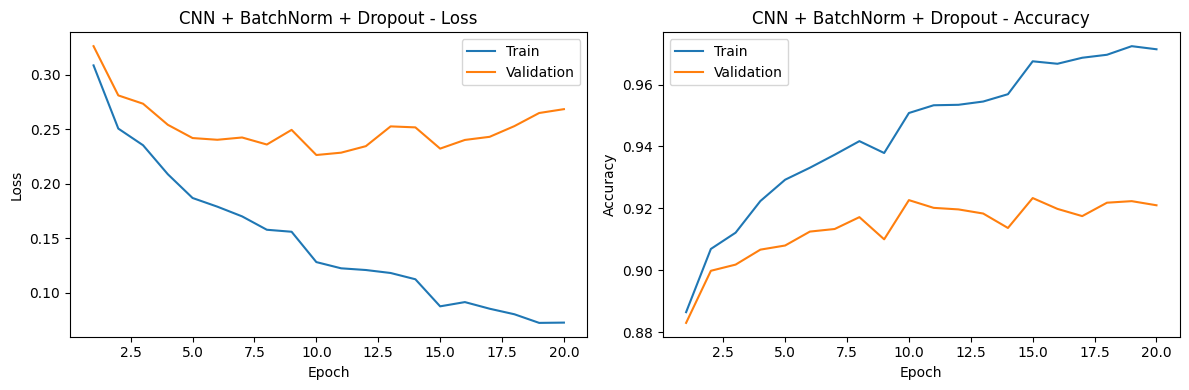

CNN sederhana        | selisih acc (train-val): 0.0635 | selisih loss (val-train): 0.2385
CNN + BN + Dropout   | selisih acc (train-val): 0.0504 | selisih loss (val-train): 0.1957


In [18]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.
history_cnn_bn, best_val_cnn_bn = train_model(cnn_bn)
plot_history(history_cnn_bn, "CNN + BatchNorm + Dropout")

# Selisih train vs validation pada epoch terakhir (indikator overfitting)
for name, h in [("CNN sederhana", history_cnn), ("CNN + BN + Dropout", history_cnn_bn)]:
    gap_acc = h["train_acc"][-1] - h["val_acc"][-1]
    gap_loss = h["val_loss"][-1] - h["train_loss"][-1]
    print(f"{name:20s} | selisih acc (train-val): {gap_acc:.4f} | selisih loss (val-train): {gap_loss:.4f}")

In [19]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
pred_cnn_bn = predict(cnn_bn, test_loader)
print("Test accuracy CNN + BN + Dropout:", round(accuracy_score(y_test, pred_cnn_bn), 4))

Test accuracy CNN + BN + Dropout: 0.9254


# 4. Evaluasi Model

In [20]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.
models = {"ANN": ann, "CNN Sederhana": cnn, "CNN + BN + Dropout": cnn_bn}
preds = {"ANN": pred_ann, "CNN Sederhana": pred_cnn, "CNN + BN + Dropout": pred_cnn_bn}
best_val = {"ANN": best_val_ann, "CNN Sederhana": best_val_cnn, "CNN + BN + Dropout": best_val_cnn_bn}

rows = []
for name in models:
    p, r, f1, _ = precision_recall_fscore_support(y_test, preds[name], average="macro", zero_division=0)
    rows.append({
        "Model": name,
        "Parameter": count_params(models[name]),
        "Val Acc (terbaik)": best_val[name],
        "Test Accuracy": accuracy_score(y_test, preds[name]),
        "Precision (macro)": p,
        "Recall (macro)": r,
        "F1-Score (macro)": f1,
    })
results = pd.DataFrame(rows).set_index("Model")

# Model terbaik dipilih berdasarkan validation accuracy (bukan test set) agar test set tetap bersih
best_name = results["Val Acc (terbaik)"].idxmax()
best_model, best_pred = models[best_name], preds[best_name]
print("Model terbaik (berdasarkan validation accuracy):", best_name)
results.round(4)

Model terbaik (berdasarkan validation accuracy): CNN Sederhana


,Parameter,Val Acc (terbaik),Test Accuracy,Precision (macro),Recall (macro),F1-Score (macro)
Model,,,,,,
ANN,235146,0.8970,0.8962,0.8961,0.8962,0.8957
CNN Sederhana,421642,0.9280,0.9262,0.9259,0.9262,0.9254
CNN + BN + Dropout,421834,0.9233,0.9254,0.9258,0.9254,0.9255


In [21]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.
print(f"Classification report - {best_name}\n")
print(classification_report(y_test, best_pred, target_names=class_names, digits=4))

Classification report - CNN Sederhana

              precision    recall  f1-score   support

 T-shirt/top     0.8454    0.9080    0.8756      1000
     Trouser     0.9900    0.9930    0.9915      1000
    Pullover     0.8915    0.8710    0.8811      1000
       Dress     0.9229    0.9450    0.9338      1000
        Coat     0.8622    0.9200    0.8902      1000
      Sandal     0.9929    0.9810    0.9869      1000
       Shirt     0.8388    0.7180    0.7737      1000
     Sneaker     0.9668    0.9610    0.9639      1000
         Bag     0.9920    0.9870    0.9895      1000
  Ankle boot     0.9569    0.9780    0.9674      1000

    accuracy                         0.9262     10000
   macro avg     0.9259    0.9262    0.9254     10000
weighted avg     0.9259    0.9262    0.9254     10000



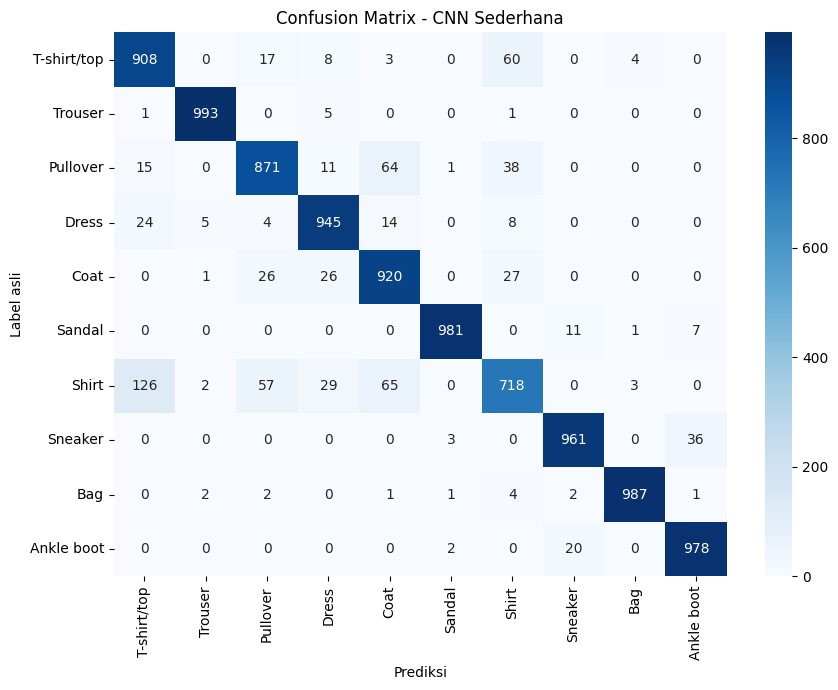

Kesalahan terbanyak (label asli -> prediksi):
  Shirt        -> T-shirt/top : 126 gambar
  Shirt        -> Coat        : 65 gambar
  Pullover     -> Coat        : 64 gambar
  T-shirt/top  -> Shirt       : 60 gambar
  Shirt        -> Pullover    : 57 gambar
  Pullover     -> Shirt       : 38 gambar


In [22]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?
cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediksi"); plt.ylabel("Label asli")
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()

# Pasangan kelas yang paling sering tertukar (di luar diagonal)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
top = np.dstack(np.unravel_index(np.argsort(cm_off.ravel())[::-1][:6], cm_off.shape))[0]
print("Kesalahan terbanyak (label asli -> prediksi):")
for i, j in top:
    print(f"  {class_names[i]:12s} -> {class_names[j]:12s}: {cm_off[i, j]} gambar")

**Pasangan kelas yang paling sering tertukar:** isi dengan hasil cetakan di atas (misalnya *Shirt* dengan *T-shirt/top*, dst.) dan jelaskan mengapa pasangan tersebut sulit dibedakan pada resolusi 28×28.

Jumlah salah prediksi: 738 dari 10000 gambar test


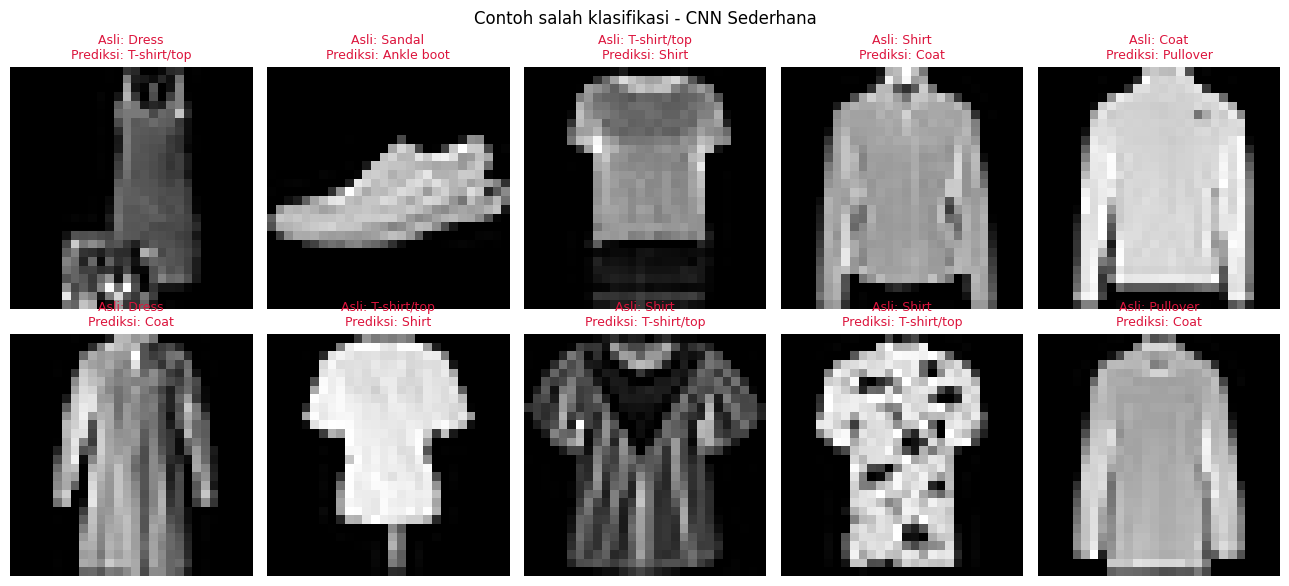

In [23]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.
wrong_idx = np.where(best_pred != y_test)[0]
print(f"Jumlah salah prediksi: {len(wrong_idx)} dari {len(y_test)} gambar test")

rng = np.random.default_rng(SEED)
sample_idx = rng.choice(wrong_idx, size=10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for ax, i in zip(axes.ravel(), sample_idx):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Asli: {class_names[y_test[i]]}\nPrediksi: {class_names[best_pred[i]]}", fontsize=9, color="crimson")
    ax.axis("off")
plt.suptitle(f"Contoh salah klasifikasi - {best_name}")
plt.tight_layout()
plt.show()

Feature map dari model: CNN Sederhana
Bentuk feature map: (32, 28, 28)


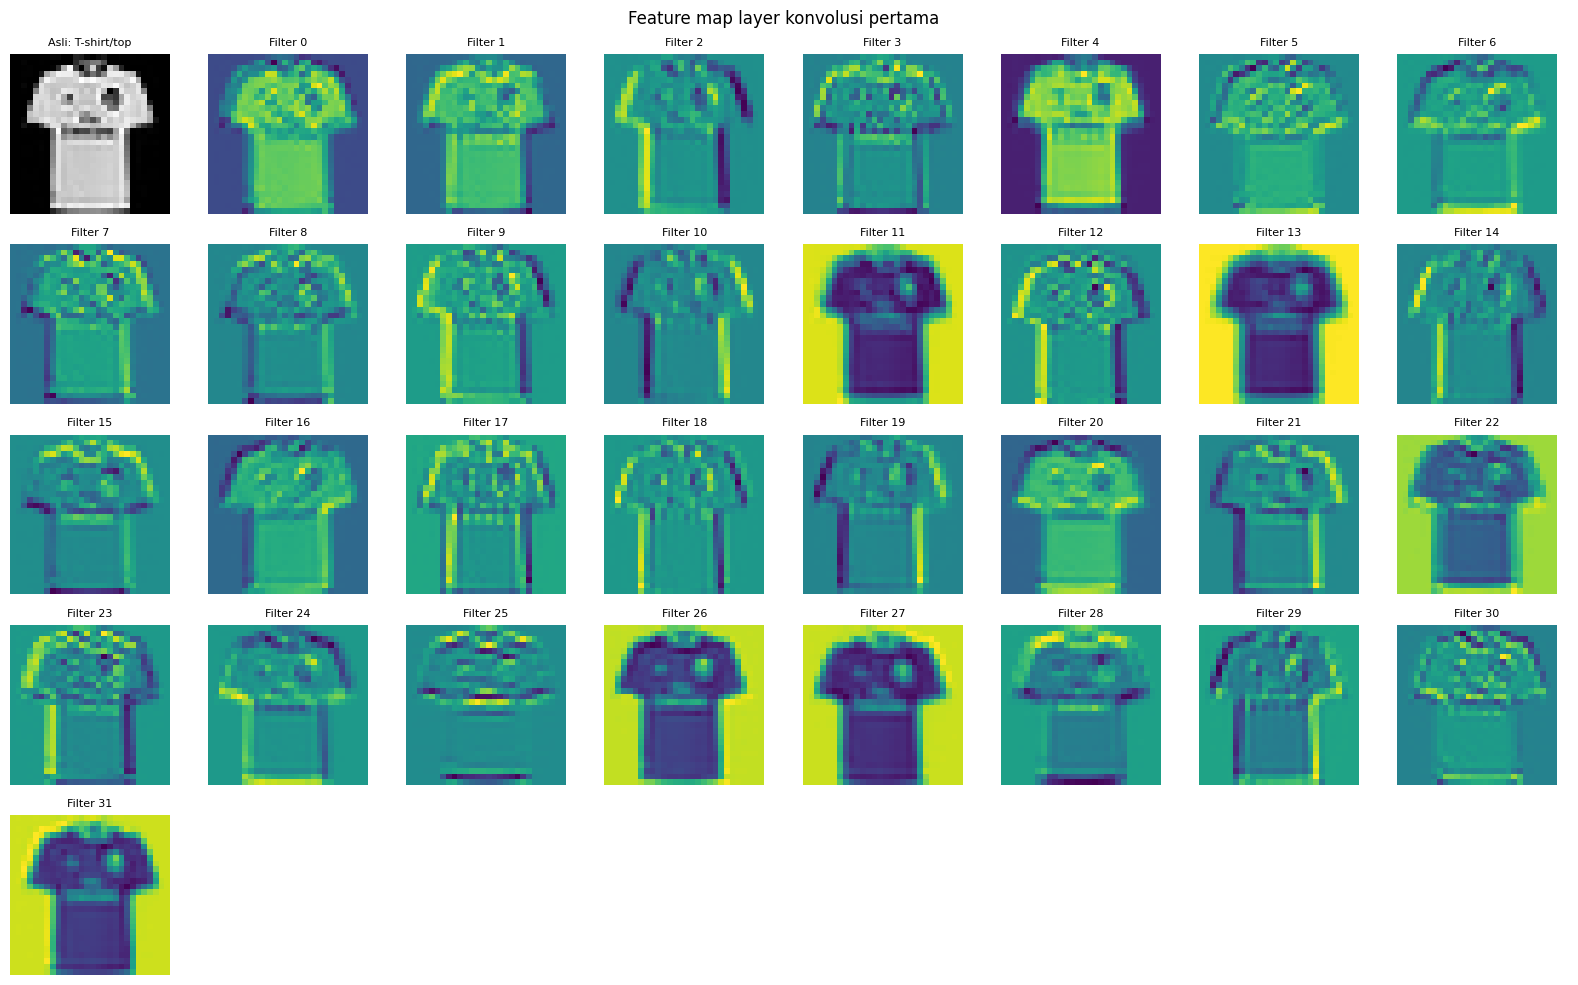

In [24]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?
# Feature map hanya ada pada model CNN. Jika model terbaik adalah ANN, pakai CNN terbaik.
cnn_names = [n for n in models if hasattr(models[n], "features")]
fm_name = best_name if best_name in cnn_names else max(cnn_names, key=lambda n: best_val[n])
fm_model = models[fm_name].eval()
print("Feature map dari model:", fm_name)

img_idx = 0
x = X_test_t[img_idx:img_idx + 1].to(device)             # (1, 1, 28, 28)
with torch.no_grad():
    fmap = fm_model.features[0](x).detach().cpu().numpy()[0]   # (32, 28, 28): hanya layer Conv2d pertama
print("Bentuk feature map:", fmap.shape)

n_ch = fmap.shape[0]
fig, axes = plt.subplots(5, 8, figsize=(16, 10))
axes[0, 0].imshow(X_test[img_idx].reshape(28, 28), cmap="gray")
axes[0, 0].set_title(f"Asli: {class_names[y_test[img_idx]]}", fontsize=8)
for k, ax in enumerate(axes.ravel()[1:n_ch + 1]):
    ax.imshow(fmap[k], cmap="viridis")
    ax.set_title(f"Filter {k}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Feature map layer konvolusi pertama")
plt.tight_layout()
plt.show()

**Pola yang ditangkap filter:** isi berdasarkan gambar di atas. Perhatikan filter mana yang responsif terhadap tepi horizontal, tepi vertikal, tepi diagonal, area terang/gelap, atau kontur siluet pakaian.

In [26]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.
# 1) Simpan bobot
torch.save(best_model.state_dict(), "model.pth")

# 2) Simpan definisi class model agar bisa di-import pada tugas Deployment
model_class = type(best_model)
with open("model_def.py", "w") as f:
    f.write("""import torch
import torch.nn as nn

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))
""")

# 3) Simpan metadata yang dibutuhkan saat inferensi
meta = {"model_class": model_class.__name__, "class_names": class_names,
        "input_shape": [1, 28, 28], "normalisasi": "pixel / 255.0"}
with open("model_meta.json", "w") as f:
    json.dump(meta, f, indent=2)

print("Model terbaik :", best_name, f"({model_class.__name__})")
print("File tersimpan: model.pth, model_def.py, model_meta.json")

# 4) Verifikasi: muat ulang dari file dan pastikan hasilnya sama
import importlib, model_def
importlib.reload(model_def)
loaded = getattr(model_def, model_class.__name__)().to(device)
loaded.load_state_dict(torch.load("model.pth", map_location=device))
pred_loaded = predict(loaded, test_loader)
print("Akurasi model hasil load:", round(accuracy_score(y_test, pred_loaded), 4),
      "| sama dengan model asli:", bool((pred_loaded == best_pred).all()))

Model terbaik : CNN Sederhana (CNN)
File tersimpan: model.pth, model_def.py, model_meta.json
Akurasi model hasil load: 0.9262 | sama dengan model asli: True


# 5. Analisis

### Hasil Analisis Eksperimen

Berdasarkan eksperimen yang telah dilakukan, berikut adalah analisis mendalam mengenai performa masing-masing model:

1. **Perbandingan Performa:**
   Dari tabel evaluasi, model **ANN** mencapai test accuracy **89.62%** (F1 macro **0.8957**) dengan **235.146** parameter. Model **CNN Sederhana** berhasil mencapai test accuracy **92.62%** (F1 macro **0.9254**) dengan **421.642** parameter. Sementara itu, **CNN + BN + Dropout** menghasilkan test accuracy **92.54%** (F1 macro **0.9255**) dengan **421.834** parameter. Model terbaik secara keseluruhan berdasarkan validation accuracy adalah **CNN Sederhana** (Val Acc **92.80%**).

2. **Jumlah Parameter vs Cara Memproses Gambar:**
   ANN meratakan gambar menjadi vektor satu dimensi berukuran 784, yang menyebabkan hilangnya informasi spasial (posisi antar-piksel). Sebaliknya, CNN menggunakan operasi konvolusi dengan filter berukuran 3×3 yang bergeser di sepanjang gambar (*weight sharing*). Desain ini sangat efektif untuk menangkap fitur lokal yang penting seperti bentuk kerah, lengan, tepi, dan lipatan pakaian.
   Meskipun jumlah parameter CNN Sederhana (**421.642**) jauh lebih besar dibandingkan ANN (**235.146**), sebagian besar parameter tersebut terpusat pada layer *Linear* pertama setelah proses *Flatten* (3.136 input neuron ke 128 hidden neuron). Peningkatan akurasi sekitar **3%** sangat sepadan karena model CNN jauh lebih mampu mengenali pola spasial pakaian secara presisi.

3. **Pengaruh Batch Normalization dan Dropout pada Learning Curve:**
   - **CNN Sederhana:** Memiliki selisih akurasi train-val pada epoch terakhir sebesar **0.0635** (6.35%) dan selisih loss sebesar **0.2385**, menunjukkan kecenderungan *overfitting* yang lebih tinggi seiring bertambahnya epoch.
   - **CNN + BN + Dropout:** Selisih akurasi train-val berhasil ditekan menjadi hanya **0.0504** (5.04%) dengan selisih loss **0.1957**.
   Penerapan Dropout membantu mengurangi tingkat *overfitting* secara signifikan dengan mencegah ko-adaptasi neuron. Batch Normalization membuat proses latihan lebih stabil sejak epoch awal, meskipun ada sedikit kompromi pada akurasi akhir dibandingkan CNN biasa.

4. **Kelas yang Sulit Dibedakan:**
   Berdasarkan classification report dan confusion matrix, kelas dengan F1-Score terendah adalah **Shirt** (F1 **0.7737**), yang sangat sering tertukar dengan **T-shirt/top** (sebanyak **126 gambar**) dan dengan **Coat** (sebanyak **65 gambar**). Di sisi lain, kelas yang paling mudah diidentifikasi dengan akurasi sangat tinggi adalah **Trouser** (F1 **0.9915**) dan **Bag** (F1 **0.9895**). Hal ini selaras dengan analisis visual awal di mana siluet atasan berlengan panjang dan pendek cenderung mirip pada resolusi rendah (28×28 piksel).

# 6. Kesimpulan dan Saran

### Kesimpulan dan Saran

#### Kesimpulan
- Model **CNN Sederhana** memberikan performa terbaik pada klasifikasi pakaian Fashion-MNIST dengan test accuracy **92.62%** dan dipilih sebagai model utama untuk dideploy ke file `model.pth` dan `model_def.py`.
- Arsitektur CNN terbukti jauh lebih unggul dibandingkan ANN konvensional karena kemampuannya mempertahankan informasi spasial gambar melalui filter konvolusi.
- Penambahan **Batch Normalization** dan **Dropout** berhasil mereduksi tingkat overfitting dan mempersempit gap kurva antara training dan validation, meskipun performa akurasi akhirnya relatif setara dengan CNN standar.
- Tingkat kesalahan klasifikasi tertinggi masih didominasi oleh kelas-kelas atasan yang secara visual sangat mirip seperti **Shirt**, **T-shirt/top**, dan **Coat**.

#### Saran
- **Data Augmentation:** Menerapkan teknik augmentasi gambar seperti horizontal flip acak atau rotasi kecil saat training untuk meningkatkan generalisasi model terhadap variasi bentuk pakaian.
- **Optimasi Arsitektur:** Menambahkan kedalaman jaringan (*deepening*) dengan menambahkan blok konvolusi ketiga atau mencoba arsitektur modern yang lebih kompleks seperti arsitektur ResNet mini.
- **Fokus Fitur:** Menggunakan teknik penyeimbangan bobot loss (*weighted loss*) khusus pada kelas yang sulit dibedakan (seperti *Shirt*) agar model memberikan perhatian lebih pada kelas-kelas tersebut.